# 05 – Lösungsblatt und Kacheln

**Ziel.** Die "Übungsaufgaben mit Lösung" für das Netz herstellen: Bildkacheln von 512 × 512 Pixeln und zu jeder ein gleich grosses **Lösungsblatt**, in dem für jeden Pixel steht, ob er Parkfläche ist. Das geschieht viermal: für zwei Bilder und zwei Auflösungen.

| Versuch | Luftbild | Auflösungen |
| --- | --- | --- |
| **A** | Frühjahr 2021 (laubfrei) | 5 cm und 10 cm |
| **B** | Sommer 2024/25 (belaubt) | 5 cm und 10 cm |

**Warum.** Das Netz lernt, indem es seine Antwort Pixel für Pixel mit dem Lösungsblatt vergleicht. Am Schluss dieses Notebooks steht die wichtigste Prüfung vor dem Lernen: Wenden wir die **Zählformel auf das Lösungsblatt selbst** an, muss wieder die Zahl der gesetzten Felder herauskommen (`01b`, Abschnitt 11, E8). Erst wenn das aufgeht, wird gelernt.

**Drei Werte im Lösungsblatt.**

| Wert | Bedeutung | welche Felder |
| --- | --- | --- |
| 1 | Parkfläche | Kategorie `sichtbar` |
| 0 | keine Parkfläche | alles andere in einem erfassten Ausschnitt |
| 255 | wird nicht bewertet | `verdeckt`, `unsicher`, `Streifen`, `einzeln`, und ein Rand von 25 m um die Testblöcke |

**Eingaben:** `kaestchen.gpkg` (Notebook 04), `aufteilung.csv` (Notebook 02), `platzmasse.json` (Notebook 03), die Luftbilder beider Jahre.
**Ausgaben:** `daten/verarbeitet/kacheln/` (Bild und Lösung je Kachel, nur Lernen und Validieren), `daten/verarbeitet/loesung/` (Kategorie je Pixel für alle Ausschnitte), `daten/verarbeitet/kacheln_index.csv`, Abbildungen `05_…`.

In [1]:
import json                        # Einstellungen und Platzmasse lesen und speichern
import shutil                      # alte Kacheln löschen
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
ROH = ROOT / "daten" / "roh"                         # Rohdaten (werden nie verändert)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ABB = ROOT / "ergebnisse" / "abbildungen"            # Abbildungen

EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))   # Einstellungen früherer Notebooks
CRS, SEED, AUFLOESUNGEN_CM = EINST["CRS"], EINST["SEED"], EINST["AUFLOESUNGEN_CM"]
MASSE = json.loads((VERARB / "platzmasse.json").read_text(encoding="utf-8"))    # Platzmasse aus Notebook 03
print("Einstellungen:", {"CRS": CRS, "SEED": SEED, "AUFLOESUNGEN_CM": AUFLOESUNGEN_CM})

import numpy as np                 # Pixelraster
import pandas as pd                # Tabellen
import geopandas as gpd            # Tabellen mit Geometrie
import matplotlib.pyplot as plt    # Abbildungen
import rasterio                    # Luftbilder lesen
from rasterio.merge import merge                    # Ausschnitt aus mehreren Bilddateien zusammensetzen
from rasterio.features import rasterize, shapes     # Formen auf ein Raster malen; Raster zurück in Formen
from rasterio.transform import from_origin          # Lage eines Rasters festlegen
from shapely.geometry import box, shape             # Rechteck; Form aus einer Beschreibung

Einstellungen: {'CRS': 'EPSG:2056', 'SEED': 42, 'AUFLOESUNGEN_CM': [5, 10]}


**Einstellungen dieses Schritts.**

| Einstellung | Wert | Warum |
| --- | --- | --- |
| `KACHEL_PX` | 512 | Kachelgrösse wie in den Quellen (Henry 2021, Hellekes 2022): 25,6 m bei 5 cm, 51,2 m bei 10 cm |
| `RAND_TEST_M` | 25 m | In diesem Rand um die Testblöcke wird beim Lernen nicht bewertet, damit die Prüfung unabhängig bleibt |
| `MIN_GUELTIG` | 0,5 | Kacheln mit weniger als der Hälfte bewertbarer Pixel werden nicht verwendet |
| `VERSUCHE` | A, B | Bildordner und Spalte der Kategorie je Versuch |
| `CODE` | 0 bis 7 | Zahl je Kategorie, damit sie in ein Pixelraster passt |

In [2]:
KACHEL_PX = 512
RAND_TEST_M = 25
MIN_GUELTIG = 0.5
KACHEL_M = 51.2                                      # Seitenlänge eines Ausschnitts der Ground Truth
VERSUCHE = {"A": {"ordner": "fruehjahr_2021", "kategorie": "kat_2021", "name": "Frühjahr 2021"},
            "B": {"ordner": "sommer_2024_25", "kategorie": "kat_2024_25", "name": "Sommer 2024/25"}}
CODE = {"kein Parkfeld": 0, "sichtbar": 1, "verdeckt, belegt": 2, "verdeckt": 3, "unsicher": 4, "Streifen": 5, "einzeln": 6, "Rand um Testblock": 7}

EINST.update(KACHEL_PX=KACHEL_PX, RAND_TEST_M=RAND_TEST_M, MIN_GUELTIG=MIN_GUELTIG, VERSUCHE=VERSUCHE, CODE=CODE)   # für spätere Notebooks
(ROOT / "einstellungen.json").write_text(json.dumps(EINST, indent=2, ensure_ascii=False), encoding="utf-8")

705

## 1. Kästchen, Ausschnitte und der Rand um die Testblöcke

**Schritt 1: lesen.** Die Kästchen mit ihrer Kategorie je Bild kommen aus Notebook 04, die Gruppe je Ausschnitt aus Notebook 02. Jeder Ausschnitt wird ein Quadrat (`box`).

**Schritt 2: der Rand.** Alle Testausschnitte werden zu einer Fläche verschmolzen (`union_all`) und um 25 m vergrössert (`buffer`). Was in Lern- und Validier-Ausschnitten in diese Fläche fällt, wird nicht bewertet.

Vorher: zwei Dateien → nachher: Kästchen, Ausschnitte als Quadrate, eine Fläche "Testblöcke mit Rand".

In [3]:
felder = gpd.read_file(VERARB / "kaestchen.gpkg")                  # ein Kästchen je Feld (Notebook 04)
aufteilung = pd.read_csv(VERARB / "aufteilung.csv")                # Gruppe je Ausschnitt (Notebook 02)
quadrate = [box(i * KACHEL_M, j * KACHEL_M, (i + 1) * KACHEL_M, (j + 1) * KACHEL_M) for i, j in zip(aufteilung.i, aufteilung.j)]
ausschnitte = gpd.GeoDataFrame(aufteilung, geometry=quadrate, crs=CRS)

testrand = ausschnitte[ausschnitte.gruppe == "testen"].union_all().buffer(RAND_TEST_M)    # Testblöcke + 25 m
betroffen = ausschnitte[(ausschnitte.gruppe != "testen") & ausschnitte.intersects(testrand)]
print(f"Kästchen: {len(felder)} | Ausschnitte: {len(ausschnitte)}")
print(f"Lern- und Validier-Ausschnitte, die den Rand berühren: {len(betroffen)} von {int((ausschnitte.gruppe != 'testen').sum())}")

Kästchen: 3269 | Ausschnitte: 691
Lern- und Validier-Ausschnitte, die den Rand berühren: 97 von 554


## 2. Ein Ausschnitt Schritt für Schritt

**Schritt 1: ein Beispiel wählen.** Der Lern-Ausschnitt mit den meisten sichtbaren Feldern im Bild 2021.

In [4]:
sichtbar_je_ausschnitt = felder[felder.kat_2021 == "sichtbar"].kachel.value_counts()       # sichtbare Felder je Ausschnitt
lern = ausschnitte[ausschnitte.gruppe == "lernen"]
beispiel = lern.loc[lern.kachel.map(sichtbar_je_ausschnitt).fillna(0).idxmax()]            # Zeile mit dem grössten Wert
print("Beispiel:", beispiel.kachel, "| Block", beispiel.block, "| sichtbare Felder 2021:", int(sichtbar_je_ausschnitt[beispiel.kachel]))

Beispiel: k_52408_24357 | Block 38 | sichtbare Felder 2021: 42


**Schritt 2: die Kategorie je Pixel malen (Rasterisieren).** `rasterize` malt Formen auf ein Pixelraster: Jeder Pixel, dessen Mitte in einer Form liegt, bekommt die Zahl dieser Form. Damit das Raster weiss, wo es liegt, braucht es eine *Lage*: `from_origin(links, oben, Pixelgrösse, Pixelgrösse)`.

Die Reihenfolge zählt, denn spätere Formen übermalen frühere:
1. zuerst die nicht bewerteten Kategorien (Codes 2 bis 6),
2. dann die sichtbaren Felder (Code 1): Überlappt ein sichtbares Feld ein verdecktes, gewinnt das sichtbare,
3. zuletzt der Rand um die Testblöcke (Code 7), nur in Lern- und Validier-Ausschnitten.

In [5]:
def kategorie_raster(ausschnitt, spalte, pixel_m):
    # Malt die Felder eines Ausschnitts auf ein Raster. Der Wert jedes Pixels ist der Code seiner Kategorie.
    links, unten, rechts, oben = ausschnitt.geometry.bounds
    seite_px = int(round(KACHEL_M / pixel_m))                       # 1024 Pixel bei 5 cm, 512 bei 10 cm
    nahe = felder[felder.intersects(ausschnitt.geometry)]           # Felder, die den Ausschnitt berühren
    formen = []                                                     # Liste aus (Form, Code)
    for form, kategorie in zip(nahe.geometry, nahe[spalte]):
        if kategorie not in ("kein Parkfeld", "sichtbar"):
            formen.append((form, CODE[kategorie]))                  # 1. nicht bewertete Kategorien
    for form in nahe[nahe[spalte] == "sichtbar"].geometry:
        formen.append((form, CODE["sichtbar"]))                     # 2. sichtbare Felder übermalen sie
    if ausschnitt.gruppe != "testen" and ausschnitt.geometry.intersects(testrand):
        formen.append((testrand, CODE["Rand um Testblock"]))        # 3. Rand um Testblöcke zuletzt
    if not formen:
        return np.zeros((seite_px, seite_px), dtype="uint8")        # Ausschnitt ohne Feld: alles 0
    return rasterize(formen, out_shape=(seite_px, seite_px), transform=from_origin(links, oben, pixel_m, pixel_m), fill=0, dtype="uint8")

kategorie = kategorie_raster(beispiel, "kat_2021", 0.05)
werte, anzahl = np.unique(kategorie, return_counts=True)            # welche Codes kommen wie oft vor?
print("Raster:", kategorie.shape, "| Pixel je Code:", {int(w): int(a) for w, a in zip(werte, anzahl)})

Raster: (1024, 1024) | Pixel je Code: {0: 849628, 1: 198948}


**Schritt 3: von der Kategorie zum Lösungsblatt.** Code 0 bleibt 0, Code 1 bleibt 1, alle anderen Codes werden 255. `np.where(Bedingung, dann, sonst)` setzt das Pixel für Pixel um.

In [6]:
def loesungsblatt(kategorie):
    # 0 = keine Parkfläche, 1 = Parkfläche, 255 = wird nicht bewertet
    return np.where(kategorie == 0, 0, np.where(kategorie == 1, 1, 255)).astype("uint8")

loesung = loesungsblatt(kategorie)
print("Anteile im Lösungsblatt:", {wert: f"{(loesung == wert).mean():.1%}" for wert in [0, 1, 255]})

Anteile im Lösungsblatt: {0: '81.0%', 1: '19.0%', 255: '0.0%'}


**Schritt 4: das Luftbild dazu lesen.** Die Luftbilder liegen als grosse Dateien vor. `merge` setzt den verlangten Ausschnitt aus den Dateien zusammen, die ihn berühren. Wir öffnen die Dateien je Versuch einmal und lassen sie offen.

Das 10-cm-Bild entsteht aus dem 5-cm-Bild: Je 2 × 2 Pixel werden gemittelt (`01b`, Abschnitt 2). So unterscheidet sich nur die Auflösung, nicht die Aufnahme.

In [7]:
QUELLEN = {}                                                        # geöffnete Bilddateien je Versuch
for versuch, angaben in VERSUCHE.items():
    QUELLEN[versuch] = [rasterio.open(pfad) for pfad in sorted((ROH / "orthofoto" / angaben["ordner"]).glob("*.tif"))]
    print(f"Versuch {versuch} ({angaben['name']}): {len(QUELLEN[versuch])} Bilddateien")

def lies_bild(versuch, rahmen):
    # Liest den Rahmen (links, unten, rechts, oben) bei 5 cm: Rot, Grün, Blau als Zahlen 0 bis 255
    bild, _ = merge(QUELLEN[versuch], bounds=rahmen, res=0.05, indexes=[1, 2, 3])
    return bild

Versuch A (Frühjahr 2021): 6 Bilddateien
Versuch B (Sommer 2024/25): 9 Bilddateien


In [8]:
def halbiere(bild):
    # Mittelt je 2 × 2 Pixel: aus 5 cm wird 10 cm. (Summe + 2) // 4 rundet kaufmännisch.
    kanaele, hoehe, breite = bild.shape
    bloecke = bild.reshape(kanaele, hoehe // 2, 2, breite // 2, 2).astype("uint16")
    return ((bloecke.sum(axis=(2, 4)) + 2) // 4).astype("uint8")

bild = lies_bild("A", beispiel.geometry.bounds)
print("Bild 5 cm:", bild.shape, bild.dtype, "| Bild 10 cm:", halbiere(bild).shape)

Bild 5 cm: (3, 1024, 1024) uint8 | Bild 10 cm: (3, 512, 512)


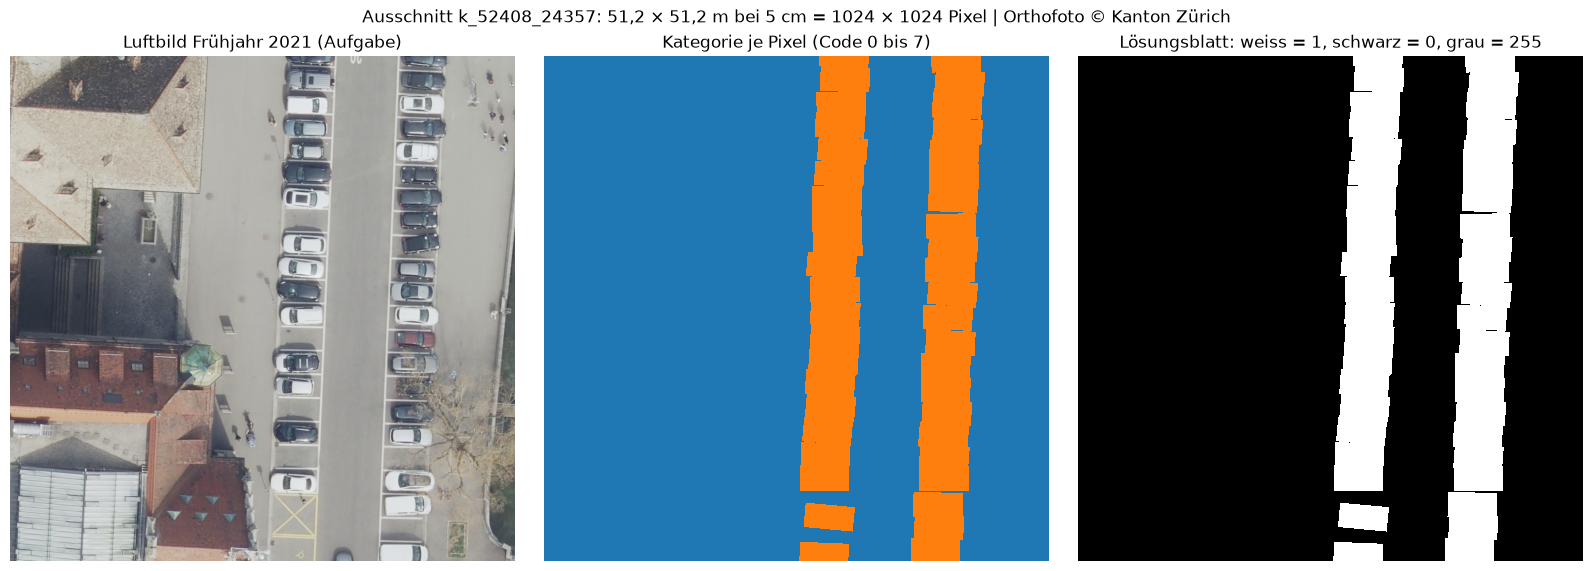

In [9]:
# Abbildung: Luftbild, Kategorie je Pixel und Lösungsblatt des Beispiel-Ausschnitts
fig, achsen = plt.subplots(1, 3, figsize=(16, 5.6), layout="constrained")
achsen[0].imshow(bild.transpose(1, 2, 0))                           # (Kanäle, Zeilen, Spalten) -> (Zeilen, Spalten, Kanäle)
achsen[0].set_title("Luftbild Frühjahr 2021 (Aufgabe)")
achsen[1].imshow(kategorie, cmap="tab10", vmin=0, vmax=9, interpolation="nearest")
achsen[1].set_title("Kategorie je Pixel (Code 0 bis 7)")
achsen[2].imshow(np.where(loesung == 255, 0.5, loesung), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
achsen[2].set_title("Lösungsblatt: weiss = 1, schwarz = 0, grau = 255")
for ax in achsen:
    ax.set_axis_off()
fig.suptitle(f"Ausschnitt {beispiel.kachel}: 51,2 × 51,2 m bei 5 cm = 1024 × 1024 Pixel | Orthofoto © Kanton Zürich")
fig.savefig(ABB / "05_loesungsblatt.png", dpi=100, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Links die Aufgabe, rechts die Lösung. In der Mitte hat jede Kategorie eine eigene Farbe. Weisse Rechtecke rechts sind sichtbare Felder; graue Flächen werden beim Lernen übersprungen.

**Schritt 5: in Kacheln schneiden.** Ein Ausschnitt hat bei 5 cm 1024 × 1024 Pixel und ergibt 2 × 2 Kacheln von 512 Pixeln. Bei 10 cm ist der ganze Ausschnitt genau eine Kachel. `bild[:, z0:z1, s0:s1]` heisst: alle Farbkanäle, Zeilen z0 bis z1, Spalten s0 bis s1.

In [10]:
def schneide(bild, loesung):
    # Teilt Bild und Lösung in Kacheln von 512 × 512 Pixeln. Ergebnis: Liste aus (Zeile, Spalte, Bildkachel, Lösungskachel)
    kacheln = []
    for zeile in range(loesung.shape[0] // KACHEL_PX):
        for spalte in range(loesung.shape[1] // KACHEL_PX):
            z0, s0 = zeile * KACHEL_PX, spalte * KACHEL_PX
            kacheln.append((zeile, spalte, bild[:, z0:z0 + KACHEL_PX, s0:s0 + KACHEL_PX], loesung[z0:z0 + KACHEL_PX, s0:s0 + KACHEL_PX]))
    return kacheln

print("5 cm:", len(schneide(bild, loesung)), "Kacheln | 10 cm:", len(schneide(halbiere(bild), loesungsblatt(kategorie_raster(beispiel, "kat_2021", 0.10)))), "Kachel")

5 cm: 4 Kacheln | 10 cm: 1 Kachel


## 3. Alle Ausschnitte, beide Versuche, beide Auflösungen

Dieselben Schritte für jeden Ausschnitt. Zwei Dinge werden gespeichert:
- die **Kategorie je Pixel** für **alle** Ausschnitte, auch die Testausschnitte (Ordner `loesung/`). Die Auswertung braucht sie am Schluss;
- **Bild und Lösung als Kacheln** nur für Lernen und Validieren (Ordner `kacheln/`). Von den Testausschnitten wird hier kein Bild gelesen.

Das Lösungsblatt für 10 cm wird direkt bei 10 cm gemalt, nicht aus dem 5-cm-Blatt verkleinert. Alte Kacheln werden vorher gelöscht, damit im Ordner nur steht, was im Index steht. Dauer: einige Minuten.

Vorher: 691 Ausschnitte → nachher: Kacheln und ein Index mit einer Zeile je Kachel.

In [11]:
def speichere_kacheln(versuch, cm, ausschnitt, bild, kategorie):
    # Schneidet einen Ausschnitt in Kacheln, speichert die bewertbaren und gibt ihre Zeilen für den Index zurück
    zeilen = []
    for zeile, spalte, bildkachel, loesungskachel in schneide(bild, loesungsblatt(kategorie)):
        gueltig = float((loesungskachel != 255).mean())     # Anteil bewertbarer Pixel
        if gueltig < MIN_GUELTIG:
            continue
        datei = f"kacheln/{versuch}_{cm}cm/{ausschnitt.kachel}_{zeile}{spalte}.npz"
        np.savez(VERARB / datei, bild=bildkachel, label=loesungskachel)
        zeilen.append(dict(versuch=versuch, aufloesung_cm=cm, gruppe=ausschnitt.gruppe, kachel=ausschnitt.kachel, datei=datei,
                           anteil_gueltig=round(gueltig, 3), anteil_park=round(float((loesungskachel == 1).mean()), 4)))
    return zeilen

Jetzt die Schleife über alle Ausschnitte. Für jeden Ausschnitt wird die Kategorie je Pixel gespeichert; für Lern- und Validier-Ausschnitte kommen die Kacheln dazu. Die alten Kacheln werden vorher entfernt, damit keine Datei aus einem früheren Lauf übrig bleibt.

In [12]:
shutil.rmtree(VERARB / "kacheln", ignore_errors=True)               # alte Kacheln entfernen
shutil.rmtree(VERARB / "loesung", ignore_errors=True)
index = []                                                          # Sammelliste für den Index
for versuch, angaben in VERSUCHE.items():
    for cm in AUFLOESUNGEN_CM:
        (VERARB / "kacheln" / f"{versuch}_{cm}cm").mkdir(parents=True)
        (VERARB / "loesung" / f"{versuch}_{cm}cm").mkdir(parents=True)
    for ausschnitt in ausschnitte.itertuples():
        bild_5cm = lies_bild(versuch, ausschnitt.geometry.bounds) if ausschnitt.gruppe != "testen" else None
        for cm in AUFLOESUNGEN_CM:
            kategorie = kategorie_raster(ausschnitt, angaben["kategorie"], cm / 100)
            np.savez_compressed(VERARB / "loesung" / f"{versuch}_{cm}cm" / f"{ausschnitt.kachel}.npz", kategorie=kategorie)
            if ausschnitt.gruppe == "testen":
                continue                                            # Testausschnitte: nur die Kategorie speichern
            bild = bild_5cm if cm == 5 else halbiere(bild_5cm)
            index += speichere_kacheln(versuch, cm, ausschnitt, bild, kategorie)   # Zeilen dieses Ausschnitts an den Index hängen
    print(f"Versuch {versuch} fertig")
index = pd.DataFrame(index)
index.to_csv(VERARB / "kacheln_index.csv", index=False)
index.groupby(["versuch", "aufloesung_cm", "gruppe"]).size().unstack()

Versuch A fertig


Versuch B fertig


gruppe                 lernen  validieren
versuch aufloesung_cm                    
A       5                1700         335
        10                458          87
B       5                1700         335
        10                456          86

## 4. Wie selten ist Parkfläche?

Parkfläche ist ein kleiner Teil der Pixel. Ein Netz, das überall "keine Parkfläche" sagt, läge fast immer richtig und wäre trotzdem nutzlos. Darum wird später nicht der Anteil richtiger Pixel gemessen, sondern die Überdeckung der Parkfläche (IoU, Notebook 07).

In [13]:
index["ohne_park"] = index.anteil_park == 0                           # True für Kacheln ganz ohne Parkfläche
tabelle = index.groupby(["versuch", "aufloesung_cm"]).agg(kacheln=("datei", "size"), mittlerer_anteil_park=("anteil_park", "mean"),
                                                          anteil_ohne_parkflaeche=("ohne_park", "mean"))   # Mittel von True/False = Anteil
tabelle.round(4)

kacheln  mittlerer_anteil_park  anteil_ohne_parkflaeche
versuch aufloesung_cm                                                         
A       5                 2035                 0.0156                   0.7558
        10                 545                 0.0144                   0.5688
B       5                 2035                 0.0102                   0.7985
        10                 542                 0.0094                   0.6328

## 5. Die Prüfung vor dem Lernen: Geht die Zählformel auf?

**Worum es geht.** Am Schluss zählt die Methode so: erkannte Fläche ÷ Platzfläche. Bevor ein Netz lernt, wenden wir genau diese Rechnung auf das **Lösungsblatt** an. Das Lösungsblatt ist die perfekte Antwort; die Rechnung muss darum die Zahl der gesetzten Felder ergeben. Weicht sie ab, ist die Formel falsch, nicht das Netz.

**Die Zählformel** (`01b`, Abschnitt 11, E7):
1. Zusammenhängende Parkfläche bildet eine Fläche (`shapes` macht aus dem Raster Formen).
2. Ihre **mittlere Tiefe** = Fläche ÷ lange Seite des kleinsten umschliessenden Rechtecks.
3. Tiefe über 3,45 m → Klasse `eng` (Platzfläche aus Notebook 03), sonst `weit`.
4. **Platz-Äquivalente** = Fläche ÷ Platzfläche der Klasse; über alle Flächen eines Ausschnitts summiert.
5. Gerundet wird einmal je Ausschnitt: `np.floor(x + 0.5)` rundet kaufmännisch.

**Schritt 1: die Formel als Funktion, am Beispiel-Ausschnitt.**

In [14]:
def platz_aequivalente(maske, pixel_m):
    # Zählt die Parkfläche einer Maske (True = Parkfläche) in Platz-Äquivalenten.
    summe = 0.0
    lage = from_origin(0, 0, pixel_m, pixel_m)                       # Pixel -> Meter (die genaue Lage spielt hier keine Rolle)
    for beschreibung, _ in shapes(maske.astype("uint8"), mask=maske, transform=lage):
        flaeche = shape(beschreibung)                                # eine zusammenhängende Fläche in Metern
        ecken = np.array(flaeche.minimum_rotated_rectangle.exterior.coords)   # kleinstes umschliessendes Rechteck
        kanten = ecken[1:3] - ecken[0:2]                             # seine zwei Kanten als Vektoren
        lange_seite = np.hypot(kanten[:, 0], kanten[:, 1]).max()
        tiefe = flaeche.area / lange_seite                           # mittlere Tiefe der Fläche
        klasse = "eng" if tiefe > MASSE["TIEFE_GRENZE_M"] else "weit"
        summe += flaeche.area / MASSE[klasse]["flaeche_m2"]
    return summe

aequivalente = platz_aequivalente(loesung == 1, 0.05)
print(f"Beispiel {beispiel.kachel}: {aequivalente:.2f} Platz-Äquivalente → gerundet {int(np.floor(aequivalente + 0.5))} | gesetzte sichtbare Felder: {int(sichtbar_je_ausschnitt[beispiel.kachel])}")

Beispiel k_52408_24357: 40.15 Platz-Äquivalente → gerundet 40 | gesetzte sichtbare Felder: 42


**Schritt 2: für alle Lern-Ausschnitte.** Für jeden Lern-Ausschnitt vergleichen wir die Formel mit der Zahl der sichtbaren Felder, deren Ring im Ausschnitt liegt. Der Rand um die Testblöcke wird für diese Prüfung nicht ausgeblendet (wir lesen die Kategorie 1 direkt), damit Formel und Felder dasselbe meinen.

Vorher: Lern-Ausschnitte → nachher: je Ausschnitt die Zahl der Felder und das Ergebnis der Formel.

In [15]:
zeilen = []
for versuch, cm in [("A", 5), ("A", 10), ("B", 5), ("B", 10)]:
    spalte = VERSUCHE[versuch]["kategorie"]
    wahr_je_ausschnitt = felder[felder[spalte] == "sichtbar"].kachel.value_counts()
    for ausschnitt in ausschnitte[ausschnitte.gruppe == "lernen"].itertuples():
        formen = [(form, 1) for form in felder[(felder[spalte] == "sichtbar") & felder.intersects(ausschnitt.geometry)].geometry]
        if not formen:
            continue                                                 # Ausschnitt ohne sichtbares Feld
        links, unten, rechts, oben = ausschnitt.geometry.bounds
        seite_px = int(round(KACHEL_M * 100 / cm))
        maske = rasterize(formen, out_shape=(seite_px, seite_px), transform=from_origin(links, oben, cm / 100, cm / 100), fill=0, dtype="uint8") == 1
        aequivalente = platz_aequivalente(maske, cm / 100)
        zeilen.append(dict(versuch=versuch, cm=cm, kachel=ausschnitt.kachel, felder=int(wahr_je_ausschnitt.get(ausschnitt.kachel, 0)),
                           aequivalente=aequivalente, gezaehlt=int(np.floor(aequivalente + 0.5))))
formel = pd.DataFrame(zeilen)
formel["betrag_fehler"] = (formel.gezaehlt - formel.felder).abs()    # Betrag von Formel minus Wahrheit, je Ausschnitt
pruefung = formel.groupby(["versuch", "cm"]).agg(ausschnitte=("kachel", "size"), felder=("felder", "sum"), aequivalente=("aequivalente", "sum"),
                                                 gezaehlt=("gezaehlt", "sum"), mittlerer_betrag_fehler=("betrag_fehler", "mean"))
pruefung["verhaeltnis"] = pruefung.aequivalente / pruefung.felder   # 1,00 = die Formel geht genau auf
pruefung.round(3)

ausschnitte  felder  aequivalente  gezaehlt  \
versuch cm                                                
A       5           203    1655      1668.853      1666   
        10          203    1655      1665.168      1662   
B       5           171    1091      1096.016      1097   
        10          171    1091      1094.817      1094   

            mittlerer_betrag_fehler  verhaeltnis  
versuch cm                                        
A       5                     0.438        1.008  
        10                    0.429        1.006  
B       5                     0.363        1.005  
        10                    0.357        1.003

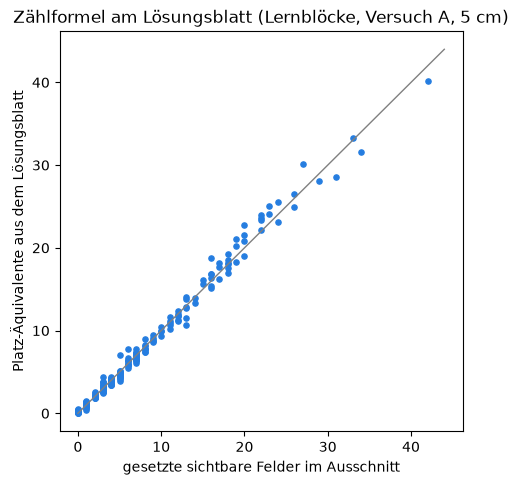

In [16]:
# Abbildung: Formel gegen gesetzte Felder je Lern-Ausschnitt (Versuch A, 5 cm). Punkte auf der Diagonale = Formel geht auf.
auswahl = formel[(formel.versuch == "A") & (formel.cm == 5)]
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.scatter(auswahl.felder, auswahl.aequivalente, s=14, color="#257de0")
grenze = max(auswahl.felder.max(), auswahl.aequivalente.max()) + 2
ax.plot([0, grenze], [0, grenze], color="grey", linewidth=1)         # Diagonale: Formel = Wahrheit
ax.set_xlabel("gesetzte sichtbare Felder im Ausschnitt")
ax.set_ylabel("Platz-Äquivalente aus dem Lösungsblatt")
ax.set_title("Zählformel am Lösungsblatt (Lernblöcke, Versuch A, 5 cm)")
fig.savefig(ABB / "05_zaehlformel.png", dpi=130, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Jeder Punkt ist ein Lern-Ausschnitt. Liegen die Punkte auf der grauen Linie, gibt die Formel die Zahl der gesetzten Felder wieder. Punkte knapp daneben entstehen an den Rändern: Ein Kästchen, das über die Kante eines Ausschnitts ragt, zählt mit seiner Fläche in zwei Ausschnitten, sein Ring aber nur in einem.

**Wie man die Tabelle liest.** `verhaeltnis` nahe 1,00 heisst: Über alle Lern-Ausschnitte geht die Formel auf. `mittlerer_betrag_fehler` sagt, um wie viele Plätze die Formel je Ausschnitt im Mittel danebenliegt, **obwohl die Fläche perfekt ist**. Besser als das kann die Zählung eines Netzes nicht werden; diese Zahl ist die Untergrenze des Fehlers der Methode.

## 6. Sichtprüfung: Kacheln mit Lösung

Drei zufällige Lernkacheln mit Parkfläche. Cyan umrandet: Parkfläche (1). Gelb umrandet: nicht bewertet (255).

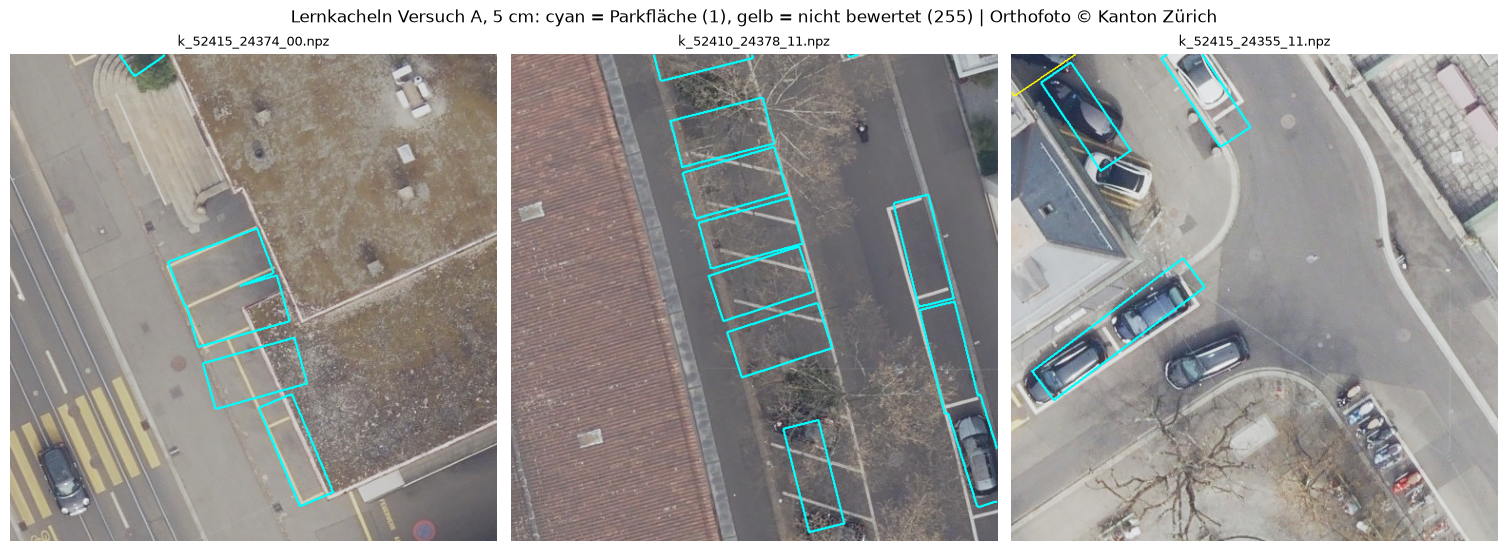

In [17]:
beispiele = index[(index.versuch == "A") & (index.aufloesung_cm == 5) & (index.gruppe == "lernen") & (index.anteil_park > 0.05)].sample(3, random_state=SEED)
fig, achsen = plt.subplots(1, 3, figsize=(15, 5.4), layout="constrained")
for ax, zeile in zip(achsen, beispiele.itertuples()):
    kachel = np.load(VERARB / zeile.datei)
    ax.imshow(kachel["bild"].transpose(1, 2, 0))
    ax.contour(kachel["label"] == 1, levels=[0.5], colors="cyan", linewidths=1.5)        # Umriss der Parkfläche
    if (kachel["label"] == 255).any():
        ax.contour(kachel["label"] == 255, levels=[0.5], colors="yellow", linewidths=1.0)   # Umriss der nicht bewerteten Fläche
    ax.set_title(Path(zeile.datei).name, fontsize=9)
    ax.set_axis_off()
fig.suptitle("Lernkacheln Versuch A, 5 cm: cyan = Parkfläche (1), gelb = nicht bewertet (255) | Orthofoto © Kanton Zürich")
fig.savefig(ABB / "05_beispielkacheln.png", dpi=100, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Bild und Lösung liegen übereinander. Die cyanfarbenen Umrisse sollten auf den aufgemalten Feldern liegen.

## Was wir gesehen haben

- Für beide Versuche und beide Auflösungen liegen Kacheln mit Lösung vor (Tabelle in Abschnitt 3). Die Testausschnitte haben nur ihre Kategorie je Pixel bekommen; ihr Bild wurde nicht gelesen.
- Parkfläche ist selten (Abschnitt 4).
- Die Zählformel, auf das Lösungsblatt angewendet, gibt die Zahl der gesetzten Felder wieder; wie genau, steht in der Tabelle von Abschnitt 5.

## Wie es weitergeht

Notebook 06 rechnet eine ganz einfache Schätzung als Vergleich (Baseline). Notebook 07 lässt das Netz lernen.